# Chapter 5 — Jacobians and acceleration kinematics
**L4: reference frames, finite differences, singularities, and acceleration.**

**Run from top to bottom.** Install the repository's `requirements-kinematics.txt` in your notebook environment, then select **Run All Cells**. No robot assets need downloading. Angles are in radians, lengths in metres, and twists are ordered $(v,\omega)$. All computations run locally; no robot commands are issued.


In [1]:
import numpy as np
import matplotlib.pyplot as plt
import pinocchio as pin
from scipy.linalg import expm

np.set_printoptions(precision=6, suppress=True)
plt.rcParams.update({'figure.figsize': (7, 4), 'axes.grid': True,
                     'axes.spines.top': False, 'axes.spines.right': False})
print('Pinocchio', pin.__version__, '| NumPy', np.__version__)
def position(q):
    q1, q2 = q
    return np.array([np.cos(q1) + np.cos(q1+q2),
                     np.sin(q1) + np.sin(q1+q2)])

def jacobian(q):
    q1, q2 = q
    return np.array([[-np.sin(q1)-np.sin(q1+q2), -np.sin(q1+q2)],
                     [ np.cos(q1)+np.cos(q1+q2),  np.cos(q1+q2)]])

def arm_points(q):
    elbow = np.array([np.cos(q[0]), np.sin(q[0])])
    return np.vstack(([0., 0.], elbow, position(q)))

def draw_arm(ax, q, label=None, **kwargs):
    xy = arm_points(q)
    ax.plot(xy[:, 0], xy[:, 1], 'o-', label=label, **kwargs)
    ax.set(xlabel='World x (m)', ylabel='World y (m)', aspect='equal')
URDF = '<robot name="course_planar_2r">\n  <link name="base"/>\n  <link name="upper_arm"/>\n  <link name="forearm"/>\n  <link name="tool"/>\n  <joint name="shoulder" type="revolute">\n    <parent link="base"/><child link="upper_arm"/>\n    <origin xyz="0 0 0" rpy="0 0 0"/><axis xyz="0 0 1"/>\n    <limit lower="-3.14159265" upper="3.14159265" effort="20" velocity="2"/>\n  </joint>\n  <joint name="elbow" type="revolute">\n    <parent link="upper_arm"/><child link="forearm"/>\n    <origin xyz="1 0 0" rpy="0 0 0"/><axis xyz="0 0 1"/>\n    <limit lower="-2.8" upper="2.8" effort="20" velocity="2"/>\n  </joint>\n  <joint name="tool_mount" type="fixed">\n    <parent link="forearm"/><child link="tool"/>\n    <origin xyz="1 0 0" rpy="0 0 0"/>\n  </joint>\n</robot>'
model = pin.buildModelFromXML(URDF)
data = model.createData()
assert model.existFrame('tool')
fid = model.getFrameId('tool')
assert (model.nq, model.nv) == (2, 2)

def tool_pose(q):
    pin.forwardKinematics(model, data, np.asarray(q, dtype=float))
    pin.updateFramePlacements(model, data)
    return data.oMf[fid].copy()  # Data is overwritten by the next algorithm call.

print('Joints:', list(model.names))
print('Tool frame id:', fid, '| nq =', model.nq, '| nv =', model.nv)


Pinocchio 3.9.0 | NumPy 2.3.5
Joints: ['universe', 'shoulder', 'elbow']
Tool frame id: 7 | nq = 2 | nv = 2


## 1. The Jacobian columns are physical velocities
At $q=(0,\pi/2)$ the planar position Jacobian is $[[-1,-1],[1,0]]$. With $\dot q=(1,-1)$, the tip moves upward at 1 m/s and has zero angular velocity at this instant.


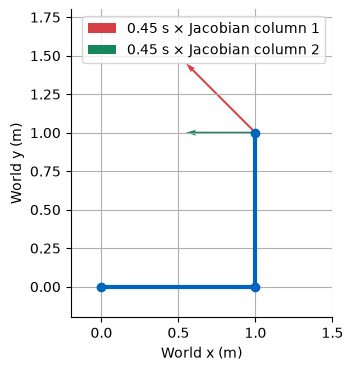

In [2]:
q = np.array([0., np.pi/2]); v = np.array([1., -1.])
Jp = jacobian(q)
np.testing.assert_allclose(Jp, [[-1,-1],[1,0]], atol=1e-12)
np.testing.assert_allclose(Jp @ v, [0,1], atol=1e-12)
fig, ax = plt.subplots()
draw_arm(ax, q, color='#0065BD', linewidth=3)
p = position(q)
for j, color in enumerate(['#D64045', '#16865C']):
    ax.quiver(*p, *(.45*Jp[:,j]), angles='xy', scale_units='xy', scale=1,
              color=color, label=f'0.45 s × Jacobian column {j+1}')
ax.set(xlim=(-.2,1.5), ylim=(-.2,1.8)); ax.legend(); plt.show()


## 2. LOCAL, WORLD, and LOCAL_WORLD_ALIGNED
For $T=(R,p)$, the three conventions satisfy
\[
\mathcal V_b=(R^T\dot p,R^T\omega),\quad
\mathcal V_s=(\dot p-\omega\times p,\omega),\quad
V_{\mathrm{LWA}}=(\dot p,\omega).
\]
`LOCAL_WORLD_ALIGNED` uses world axes **at the tool origin**. Its top three rows map joint rates to the world velocity of that origin. `WORLD` instead describes the spatial twist about the world origin. All six-vectors below are linear-first.


In [3]:
pin.computeJointJacobians(model, data, q)
pin.updateFramePlacements(model, data)
T = data.oMf[fid].copy()
Jb = pin.getFrameJacobian(model, data, fid, pin.LOCAL).copy()
Js = pin.getFrameJacobian(model, data, fid, pin.WORLD).copy()
Jlwa = pin.getFrameJacobian(model, data, fid, pin.LOCAL_WORLD_ALIGNED).copy()
np.testing.assert_allclose(Jlwa[:2], Jp, atol=1e-12)
np.testing.assert_allclose(Js, T.action @ Jb, atol=1e-12)
axes_rotation = np.zeros((6, 6))
axes_rotation[:3,:3] = T.rotation; axes_rotation[3:,3:] = T.rotation
np.testing.assert_allclose(Jlwa, axes_rotation @ Jb, atol=1e-12)
print('LOCAL:', Jb @ v, '\nWORLD:', Js @ v, '\nLOCAL_WORLD_ALIGNED:', Jlwa @ v)


LOCAL: [1. 0. 0. 0. 0. 0.] 
WORLD: [0. 1. 0. 0. 0. 0.] 
LOCAL_WORLD_ALIGNED: [0. 1. 0. 0. 0. 0.]


## 3. Check the library Jacobian against forward kinematics
This is the complete version of the code formerly on L4 slide 52. Use a **tangent** direction $v\in\mathbb R^{n_v}$, integrate $q_\pm$, and compare the central difference with $J_pv$. Recompute the pose for each perturbed configuration.

The same procedure works when $n_q\ne n_v$; adding a velocity vector to stored quaternion coordinates does not.


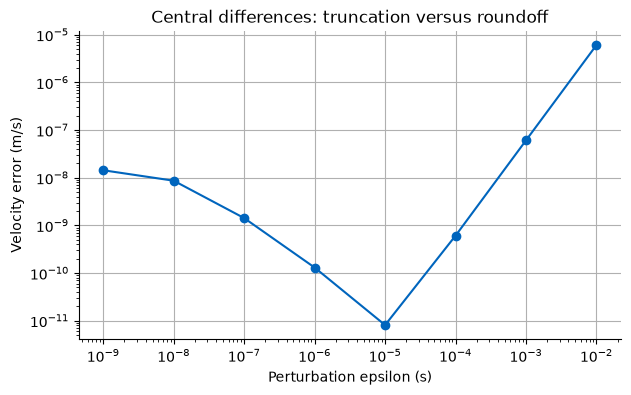

Smallest error: 8.097164127339724e-12


In [4]:
direction = np.array([.7, -.2])
epsilons = np.logspace(-2, -9, 8)
errors = []
for eps in epsilons:
    qplus = pin.integrate(model, q, eps*direction)
    qminus = pin.integrate(model, q, -eps*direction)
    dp_fd = (tool_pose(qplus).translation - tool_pose(qminus).translation)/(2*eps)
    errors.append(np.linalg.norm(dp_fd - Jlwa[:3] @ direction))
assert min(errors) < 1e-8
fig, ax = plt.subplots()
ax.loglog(epsilons, np.maximum(errors, 1e-16), 'o-', color='#0065BD')
ax.set(xlabel='Perturbation epsilon (s)', ylabel='Velocity error (m/s)',
       title='Central differences: truncation versus roundoff'); plt.show()
print('Smallest error:', min(errors))


## 4. Acceleration includes the changing Jacobian
$\ddot p=J_p\ddot q+\dot J_p\dot q$. Compare the formula, a second derivative along $q(t)=q+t v+\frac12t^2a$, and Pinocchio's **classical** frame acceleration.


In [5]:
q = np.array([.3, -.8]); v = np.array([.6, -.4]); a = np.array([.2, -.1])
def jdot(q, v):
    q1, q2 = q; v1, v2 = v
    return np.array([[-np.cos(q1)*v1-np.cos(q1+q2)*(v1+v2), -np.cos(q1+q2)*(v1+v2)],
                     [-np.sin(q1)*v1-np.sin(q1+q2)*(v1+v2), -np.sin(q1+q2)*(v1+v2)]])

expected = jacobian(q) @ a + jdot(q, v) @ v
pin.forwardKinematics(model, data, q, v, a)
pin.updateFramePlacements(model, data)
acc = pin.getFrameClassicalAcceleration(model, data, fid, pin.LOCAL_WORLD_ALIGNED).linear
np.testing.assert_allclose(acc[:2], expected, atol=1e-12)
eps = 1e-4
acc_fd = (position(q+eps*v+.5*eps**2*a) - 2*position(q)
          + position(q-eps*v+.5*eps**2*a))/eps**2
np.testing.assert_allclose(acc_fd, expected, atol=1e-7)
print('J a + Jdot v:', expected, '| Pinocchio:', acc[:2], '| finite difference:', acc_fd)

# Lecture one-link limit: keep joint 2 stationary and inspect the elbow frame.
elbow = model.getFrameId('forearm')
pin.forwardKinematics(model, data, np.zeros(2), np.array([2.,0.]), np.zeros(2))
pin.updateFramePlacements(model, data)
centripetal = pin.getFrameClassicalAcceleration(model, data, elbow, pin.LOCAL_WORLD_ALIGNED).linear
np.testing.assert_allclose(centripetal, [-4,0,0], atol=1e-12)
print('Constant-speed, unit-radius centripetal acceleration:', centripetal)


J a + Jdot v: [-0.390186  0.191615] | Pinocchio: [-0.390186  0.191615] | finite difference: [-0.390186  0.191615]
Constant-speed, unit-radius centripetal acceleration: [-4.  0.  0.]


## 5. A singularity removes a task direction
Compare the image of the unit joint-rate circle at a bent and a straight configuration. At a straight configuration, first-order tip motion is only perpendicular to the arm.


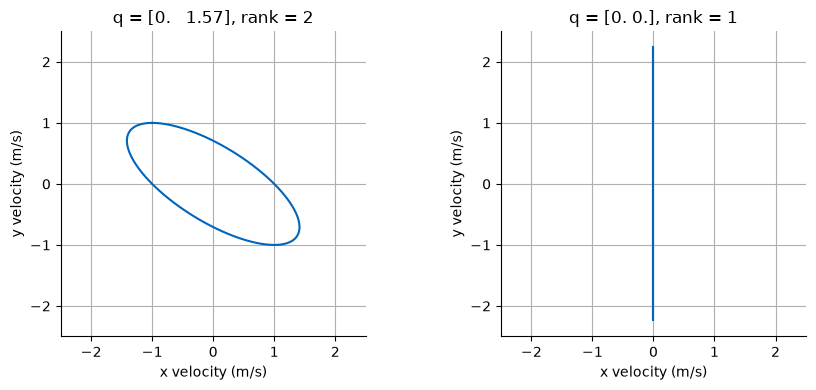

In [6]:
circle = np.vstack((np.cos(np.linspace(0,2*np.pi,201)), np.sin(np.linspace(0,2*np.pi,201))))
fig, axes = plt.subplots(1, 2, figsize=(9, 4))
for ax, angles in zip(axes, ([0., np.pi/2], [0., 0.])):
    J = jacobian(angles); curve = J @ circle
    ax.plot(curve[0], curve[1], color='#0065BD')
    ax.set(xlabel='x velocity (m/s)', ylabel='y velocity (m/s)', aspect='equal',
           xlim=(-2.5,2.5), ylim=(-2.5,2.5), title=f'q = {np.round(angles,2)}, rank = {np.linalg.matrix_rank(J)}')
plt.tight_layout(); plt.show()


## Try it
Use `WORLD[:3]` in the position finite-difference check and explain the discrepancy. Change the joint speed while keeping joint acceleration zero: why does tip acceleration remain nonzero?

Next: [Chapter 6 — Inverse kinematics](../06-inverse-kinematics/01_inverse_kinematics.ipynb).

Reference: [Pinocchio frame algorithms and conventions](https://gepettoweb.laas.fr/doc/stack-of-tasks/pinocchio/devel/doxygen-html/frames_8hpp_source.html).
